In [184]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, roc_curve
from sklearn.metrics import confusion_matrix
from sklearn.metrics import log_loss
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, classification_report, roc_curve, auc, precision_recall_curve, average_precision_score)
import warnings

In [185]:
# train 데이터를 기반으로 학습 시키는 모델을 만들기 위해 tr, te 를 사전에 구분 후 전처리 
# (이름의 경우 전체 내용 확인 후 진행이 아닌 값 변형이 아니므로 사전에 진행)
# 이후 tr 데이터를 기반으로 tr과 te 데이터의 na 값을 채우기(tr 값을 채우고 te 값을 채우는 경우 na 값이 달라지기 때문에 a,b로 사전에 지정을 한 후 적용)
train=pd.read_csv("train.csv")
train.isnull().sum()
train['Name'] = train['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)
train['Name'] = train['Name'].replace(['Lady', 'Countess', 'Capt', 'Col','Don', 'Dr', 'Major', 'Rev', 'Sir','Jonkheer', 'Dona'], 'Rare')
train['Name'] = train['Name'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
tr, te = train_test_split(train, test_size=0.25, random_state=42)

a=tr["Age"].mean()
tr["Age"] = tr["Age"].fillna(a)
te["Age"] = te["Age"].fillna(a)
tr["Age"] = tr["Age"].round()
te["Age"] = te["Age"].round()
b=tr["Embarked"].mode()[0]
tr["Embarked"] = tr["Embarked"].fillna(b)
te["Embarked"] = te["Embarked"].fillna(b)
# 버림
# tr["Age"] = tr["Age"].floor()
# te["Age"] = te["Age"].floor()
# 올림
# tr["Age"] = tr["Age"].ceil()
# te["Age"] = te["Age"].ceil()
tr.isnull().sum()
te.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          158
Embarked         0
dtype: int64

In [186]:
tr_1 = tr.drop(columns=["Name","Cabin","Ticket","Embarked","PassengerId"])
te_1 = te.drop(columns=["Name","Cabin","Ticket","Embarked","PassengerId"])
tr_1.head()
# te_1.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare
290,1,1,female,26.0,0,0,78.8500
158,0,3,male,29.0,0,0,8.6625
69,0,3,male,26.0,2,0,8.6625
517,0,3,male,29.0,0,0,24.1500
131,0,3,male,20.0,0,0,7.0500


In [187]:
# 각 column별 답의 갯수 확인 및 범주, 연속형 변수 구분 
unique_counts=tr_1.nunique()
print(unique_counts)
unique_counts=te_1.nunique()
print(unique_counts)
cat_cols=["Sex", "Pclass","SibSp", "Parch"]
con_cols=["Age","Fare"]
target_col=["Survived"]
print("The categorial cols are : ", cat_cols)
print("The continuous cols are : ", con_cols)
print("The target variable is ", target_col)

Survived      2
Pclass        3
Sex           2
Age          66
SibSp         7
Parch         7
Fare        211
dtype: int64
Survived      2
Pclass        3
Sex           2
Age          53
SibSp         5
Parch         6
Fare        103
dtype: int64
The categorial cols are :  ['Sex', 'Pclass', 'SibSp', 'Parch']
The continuous cols are :  ['Age', 'Fare']
The target variable is  ['Survived']


In [188]:
tr_1[con_cols].describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Age,599.0,29.345576,12.938591,1.0,22.000,29.0,35.000,80.0000
Fare,599.0,33.834695,52.303810,0.0,7.925,14.5,31.275,512.3292


In [189]:
# train 데이터의 na 확인
tr_1.isnull().sum()
# test 데이터의 na 확인
# te_1.isnull().sum()

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
dtype: int64

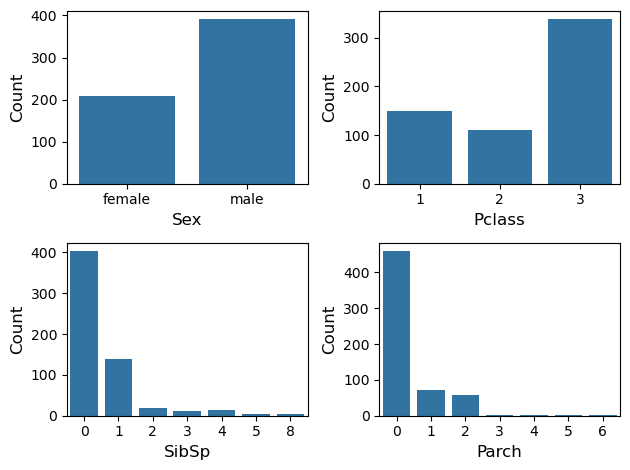

In [190]:
# 범주형 변수들의 구조 확인
for i, feature in enumerate(cat_cols,1):
    plt.subplot(2,2,i)
    sns.countplot(x=feature, data=tr_1)
    plt.ylabel("Count", fontsize=12)
    plt.xlabel(feature, fontsize=12)
    plt.tight_layout()

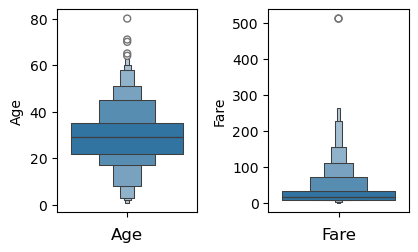

In [191]:
# 연속형 변수들에 대한 분포 확인
for i, feature in enumerate(con_cols, 1):
    plt.subplot(2,3,i)
    sns.boxenplot(y=feature, data=tr_1)
    plt.xlabel(feature, fontsize=12)
    plt.tight_layout()    

<Axes: xlabel='Survived', ylabel='count'>

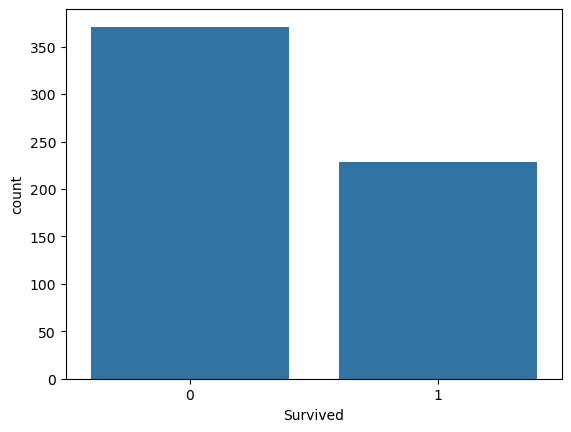

In [192]:
# 생존자의 수 확인
sns.countplot(x='Survived',data=tr_1)

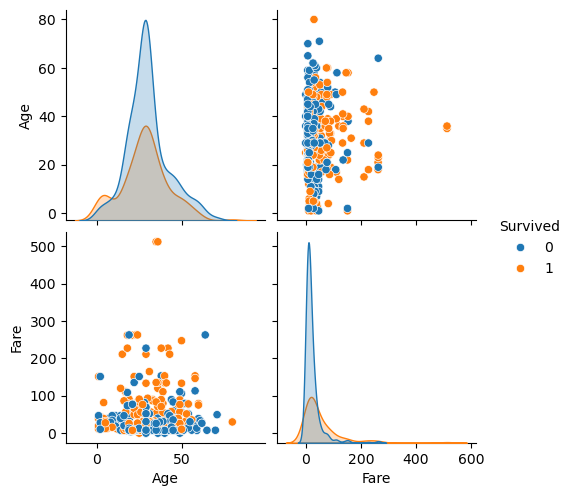

In [193]:
# 각 변수들 간의 관계 확인 -> pairplot의 경우 연속형 변수일때 확인이 효과적
sns.pairplot(tr_1[con_cols+['Survived']], hue='Survived')
plt.show()

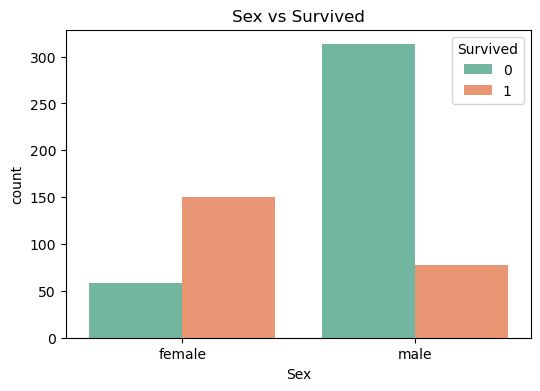

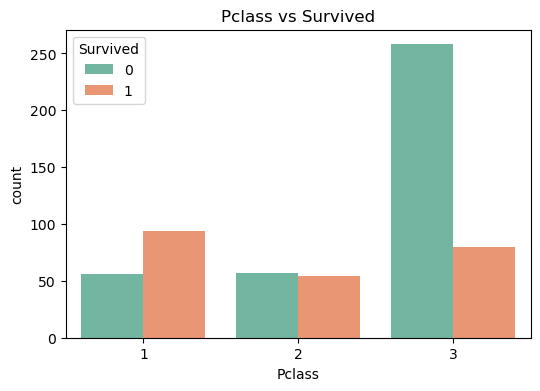

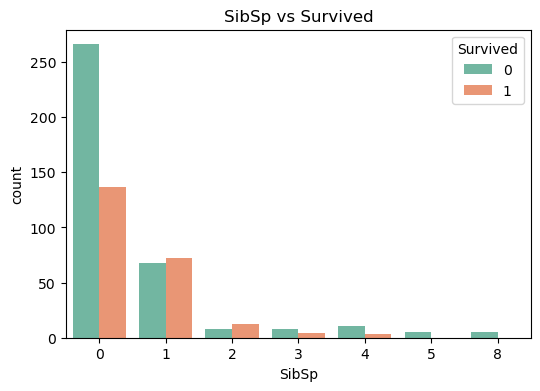

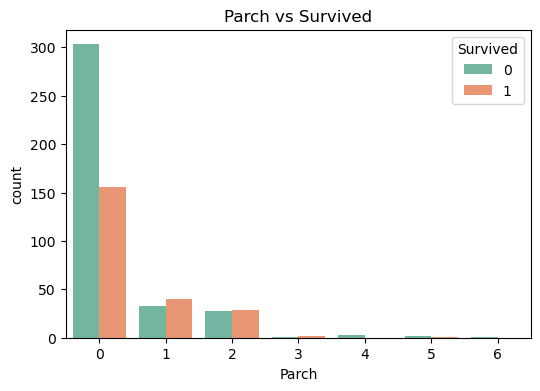

In [194]:
# 범주형 변수들의 survived 비중 확인인
for col in cat_cols:
    plt.figure(figsize=(6,4))
    sns.countplot(x=col, hue='Survived', data=tr_1, palette='Set2')
    plt.title(f'{col} vs Survived')
    plt.show()

In [195]:
# train, test 데이터 범주형 데이터 dummy 변수로 변환 후 학습 데이터 설정(pclass1의 경우는 더미변수 함정을 막기 위해 첫 범주 제거)
combined = pd.concat([tr_1, te_1], axis=0)
combined_dummies = pd.get_dummies(combined, columns=cat_cols, drop_first=True)
tr1 = combined_dummies.iloc[:len(tr_1), :].copy()
te1 = combined_dummies.iloc[len(tr_1):, :].copy()
X_tr=tr1.drop(['Survived'], axis=1)
y_tr=tr1[['Survived']]
X_te=te1.drop(['Survived'], axis=1)
y_te=te1[['Survived']]

In [196]:
print("The shape of X_train is ", X_tr.shape)
print("The shape of X_test is ",X_te.shape)
print("The shape of y_train is ", y_tr.shape)
print("The shape of y_test is ", y_te.shape)

The shape of X_train is  (599, 17)
The shape of X_test is  (200, 17)
The shape of y_train is  (599, 1)
The shape of y_test is  (200, 1)


In [197]:
# penalty를 l2로 설정을 함으로서 과적합 방지 및 일반화 성능 올리기기
# logreg의 경우 y값으로 1차원을 원하기 떄문에 ravel()로 실행 -> 하지 않아도 결과 변화 x 
# c 즉 규제 강도를 조절하며 모델의 복잡성 및 과적합 조절
# c = 0.001, 0.01, 0.1, 1, 10으로 한 결과 1이 가장 적합하다 판단 -> 좀 더 상세히 나누어 다시 확인
# for c in [1, 1.1, 1.2, 1.3, 1.4]:
#     logreg= LogisticRegression(penalty='l2', C=c, max_iter=1000)
#     logreg.fit(X_tr, y_tr.values.ravel())
#     y_pred_proba=logreg.predict_proba(X_te)
#     y_pred = np.argmax(y_pred_proba, axis=1)
#     print("c의 값은 : ",c)
#     print("The train accuracy score of Logistric regression is ", accuracy_score(y_tr, logreg.predict(X_tr)))
#     print("The test accuracy score of Logistric Regression is ", accuracy_score(y_te, y_pred))
# 결과 c=1.2 이상은 test 정확도에 차이가 없으나 train 정확도만 상승 -> 과적합 문제 가능성 존재 -> 1.2가 적합하다 판단

# 이번엔 max_iter 즉 반복 최대 횟수 조절
# max in [1, 10, 100, 1000, 10000]로 한 결과 100, 1000이 대부분의 경우 수렴한다 판단 -> 좀 더 상세히 나눠 판단
# c:\Users\user\anaconda3\envs\2025ml\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
#STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT. 인 경우는 데이터 부족
# for max in [200, 300, 400, 500, 600, 700]:
#     logreg= LogisticRegression(penalty='l2', C=1.2, max_iter=max)
#     logreg.fit(X_tr, y_tr.values.ravel())
#     y_pred_proba=logreg.predict_proba(X_te)
#     y_pred = np.argmax(y_pred_proba, axis=1)
#     print("max_iter의 값은 : ",max)
#     print("The train accuracy score of Logistric regression is ", accuracy_score(y_tr, logreg.predict(X_tr)))
#     print("The test accuracy score of Logistric Regression is ", accuracy_score(y_te, y_pred))
# # 실행 결과 300으로 결정
logreg= LogisticRegression(penalty='l2', C=1.2, max_iter=300)
logreg.fit(X_tr, y_tr.values.ravel())
y_pred_proba=logreg.predict_proba(X_te)
y_pred = np.argmax(y_pred_proba, axis=1)
print("The train accuracy score of Logistric regression is ", accuracy_score(y_tr, logreg.predict(X_tr)))
print("The test accuracy score of Logistric Regression is ", accuracy_score(y_te, y_pred))

The train accuracy score of Logistric regression is  0.8096828046744574
The test accuracy score of Logistric Regression is  0.84


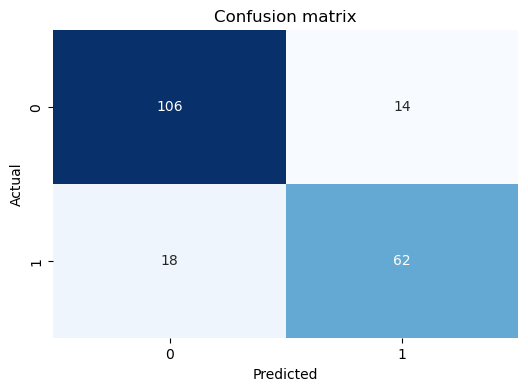

In [198]:
# test 값과 예측 값을 비교하여 예측의 정확도 확인
cm=confusion_matrix(y_te, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title("Confusion matrix")
plt.show()

In [ ]:
# 현재 test에 대하여 로그 손실 값 확인
# loss는 예측한 확률이 정답과 차이가 나는 수치 표현 -> 작을 수록 좋음
y_pred_proba_train=logreg.predict_proba(X_tr)
loss=log_loss(y_tr, y_pred_proba_train)
print("The train loss of Logistric regression is",loss)

The train loss of Logistric regression is 0.45520271856512623


In [200]:
# 위에 한 예측들을 pipeline 방식으로 확인
X_tr = tr_1[cat_cols + con_cols]
y_tr = tr_1[target_col]
X_te = te_1[cat_cols + con_cols]
y_te = te_1[target_col]
preprocessor=ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), con_cols), ("cat", OneHotEncoder(drop="first"), cat_cols)
    ]
)
# 위에서 찾은 c와 max_iter 적용
clf = Pipeline(steps=[
    ("preprocessor", preprocessor), 
    ("classifier", LogisticRegression(solver='liblinear', C=1.2, max_iter=300))
])
clf.fit(X_tr, y_tr.values.ravel())
y_pred=clf.predict(X_te)
y_proba=clf.predict_proba(X_te)[:, 1]
print("Classification Report:\n", classification_report(y_te, y_pred))

# 실행해본 결과 정확도는 84%

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.88      0.87       120
           1       0.82      0.78      0.79        80

    accuracy                           0.84       200
   macro avg       0.84      0.83      0.83       200
weighted avg       0.84      0.84      0.84       200



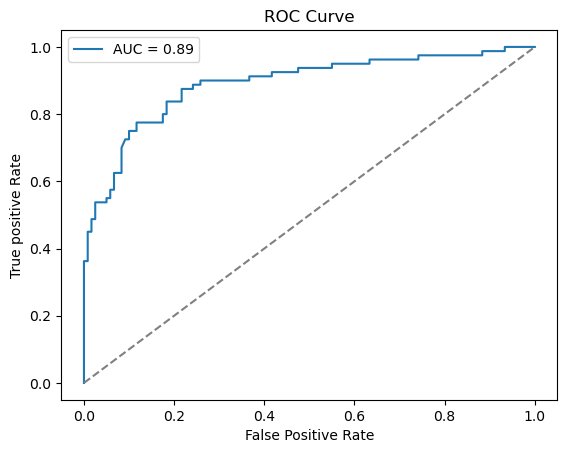

In [201]:
# x축 = 0이지만 1로 판단한 비율, y축 = 1을 1로 맞게 판단한 비율
fpr, tpr, _ = roc_curve(y_te, y_proba)
roc_auc=auc(fpr, tpr)
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
plt.plot([0,1],[0,1], linestyle="--", color="gray")
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True positive Rate")
plt.legend()
plt.show()

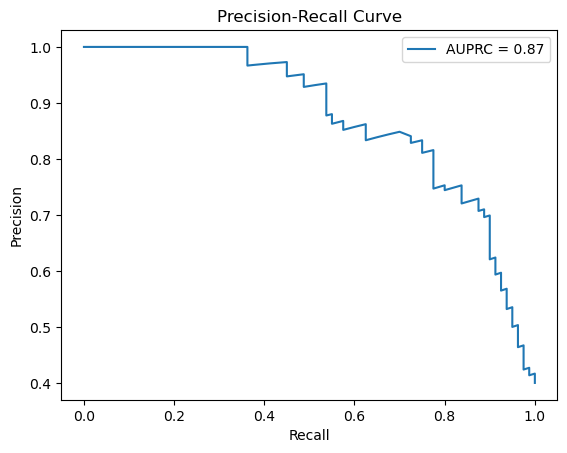

In [202]:
# x축 = 실제 1인 값 중 모델이 1이라 답한 비율
# y축 = 모델이 1이라 한 것 중 정답인 비율
precision, recall, _=precision_recall_curve(y_te, y_proba)
pr_auc=average_precision_score(y_te, y_proba)
plt.plot(recall, precision, label=f"AUPRC = {pr_auc:.2f}")
plt.title("Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.show()

In [203]:
# 지금 첫번째 테스트는 실시해본 결과 정확도는 나쁘지 않지만 사망자를 생존자를 사망자라 판단을 하여 생기는 문제들이 발생 
# 이를 해결하기 위해 class_weight='balanced'를 적용하여 생존자에 더욱 가중치 넣어보기

In [204]:
combined = pd.concat([tr_1, te_1], axis=0)
combined_dummies = pd.get_dummies(combined, columns=cat_cols, drop_first=True)
tr1 = combined_dummies.iloc[:len(tr_1), :].copy()
te1 = combined_dummies.iloc[len(tr_1):, :].copy()
X_tr=tr1.drop(['Survived'], axis=1)
y_tr=tr1[['Survived']]
X_te=te1.drop(['Survived'], axis=1)
y_te=te1[['Survived']]

In [205]:
# 가중치를 넣는 경우 더욱 복잡해지기 때문에 max, c를 재조정
# for max in [200, 300, 400, 500, 600, 700]:
#     logreg = LogisticRegression(penalty='l2', C=0.5, max_iter=max, class_weight='balanced')   
#     logreg.fit(X_tr, y_tr.values.ravel())
#     y_pred_proba=logreg.predict_proba(X_te)
#     y_pred = np.argmax(y_pred_proba, axis=1)
#     print("max_iter의 값은 : ",max)
#     print("The train accuracy score of Logistric regression is ", accuracy_score(y_tr, logreg.predict(X_tr)))
#     print("The test accuracy score of Logistric Regression is ", accuracy_score(y_te, y_pred))
# for c in [0.5, 0.75, 1, 1.25, 1.5]:
#     logreg= LogisticRegression(penalty='l2', C=c, max_iter=400, class_weight='balanced')
#     logreg.fit(X_tr, y_tr.values.ravel())
#     y_pred_proba=logreg.predict_proba(X_te)
#     y_pred = np.argmax(y_pred_proba, axis=1)
#     print("c의 값은 : ",c)
#     print("The train accuracy score of Logistric regression is ", accuracy_score(y_tr, logreg.predict(X_tr)))
#     print("The test accuracy score of Logistric Regression is ", accuracy_score(y_te, y_pred))

In [206]:
logreg= LogisticRegression(penalty='l2', C=0.75, max_iter=400, class_weight='balanced')
logreg.fit(X_tr, y_tr.values.ravel())
y_pred_proba=logreg.predict_proba(X_te)
y_pred = np.argmax(y_pred_proba, axis=1)
print("The train accuracy score of Logistric regression is ", accuracy_score(y_tr, logreg.predict(X_tr)))
print("The test accuracy score of Logistric Regression is ", accuracy_score(y_te, y_pred))

The train accuracy score of Logistric regression is  0.7679465776293823
The test accuracy score of Logistric Regression is  0.825


In [207]:
y_pred_proba_train=logreg.predict_proba(X_tr)
loss=log_loss(y_tr, y_pred_proba_train)
print("The train loss of Logistric regression is",loss)

The train loss of Logistric regression is 0.47570267111369446


In [208]:
# 다시 파이프 통해서 재확인
X_tr = tr_1[cat_cols + con_cols]
y_tr = tr_1[target_col]
X_te = te_1[cat_cols + con_cols]
y_te = te_1[target_col]
preprocessor=ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), con_cols), ("cat", OneHotEncoder(drop="first"), cat_cols)
    ]
)
# 위에서 찾은 c와 max_iter 적용
clf = Pipeline(steps=[
    ("preprocessor", preprocessor), 
    ("classifier", LogisticRegression(solver='liblinear', C=0.75, max_iter=400, class_weight='balanced'))
])
clf.fit(X_tr, y_tr.values.ravel())
y_pred=clf.predict(X_te)
y_proba=clf.predict_proba(X_te)[:, 1]
print("Classification Report:\n", classification_report(y_te, y_pred))

# 실행 결과 가중치 부여시 별로... 다른 방법 찾아보자

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.82      0.83       120
           1       0.74      0.79      0.76        80

    accuracy                           0.81       200
   macro avg       0.80      0.80      0.80       200
weighted avg       0.81      0.81      0.81       200



In [209]:
# 제거할 column 분석
tr.columns
# tr_1.columns
# unique_counts=tr.nunique()
# print(unique_counts)

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [210]:
# Embarked(출항 위치)의 경우 생존과 연관이 있을 수 있지만 na 값이 존재하여 사용하기 애매하였음 -> 최빈값으로 넣은 후 진행해보기(첫장장)
tr_2 = tr.drop(columns=["Name","Cabin","Ticket","PassengerId"])
te_2 = te.drop(columns=["Name","Cabin","Ticket","PassengerId"])
cat_cols=["Sex", "Pclass","SibSp", "Parch","Embarked"]
con_cols=["Age","Fare"]
target_col=["Survived"]

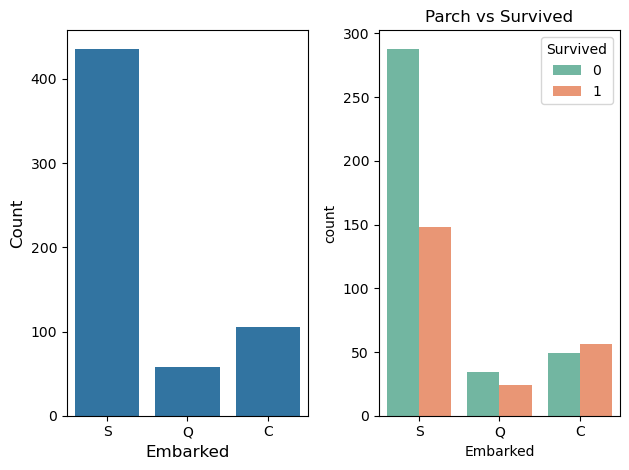

In [211]:
# Embarked 데이터에 대한 시각화화
plt.subplot(1,2,1)
sns.countplot(x="Embarked", data=tr_2)
plt.ylabel("Count", fontsize=12)
plt.xlabel("Embarked", fontsize=12)
plt.subplot(1,2,2)
sns.countplot(x="Embarked", hue='Survived', data=tr_2, palette='Set2')
plt.title(f'{col} vs Survived')
plt.tight_layout()
plt.show()

In [212]:
# Embarked 추가가
combined = pd.concat([tr_2, te_2], axis=0)
combined_dummies = pd.get_dummies(combined, columns=cat_cols, drop_first=True)
tr2 = combined_dummies.iloc[:len(tr_2), :].copy()
te2 = combined_dummies.iloc[len(tr_2):, :].copy()
X_train=tr2.drop(['Survived'], axis=1)
y_train=tr2[['Survived']]
X_test=te2.drop(['Survived'], axis=1)
y_test=te2[['Survived']]

In [213]:
# c 측정 결과 0.8일때부터 test 성능 변화 없음
for c in [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
    logreg= LogisticRegression(penalty='l2', C=c, max_iter=1000)
    logreg.fit(X_train, y_train.values.ravel())
    y_pred_proba=logreg.predict_proba(X_test)
    y_pred = np.argmax(y_pred_proba, axis=1)
    print("c의 값은 : ",c)
    print("The train accuracy score of Logistric regression is ", accuracy_score(y_train, logreg.predict(X_train)))
    print("The test accuracy score of Logistric Regression is ", accuracy_score(y_test, y_pred))

c의 값은 :  0.5
The train accuracy score of Logistric regression is  0.8063439065108514
The test accuracy score of Logistric Regression is  0.83
c의 값은 :  0.6
The train accuracy score of Logistric regression is  0.8063439065108514
The test accuracy score of Logistric Regression is  0.83
c의 값은 :  0.7
The train accuracy score of Logistric regression is  0.8046744574290484
The test accuracy score of Logistric Regression is  0.83
c의 값은 :  0.8
The train accuracy score of Logistric regression is  0.8063439065108514
The test accuracy score of Logistric Regression is  0.83
c의 값은 :  0.9
The train accuracy score of Logistric regression is  0.8080133555926544
The test accuracy score of Logistric Regression is  0.835
c의 값은 :  1.0
The train accuracy score of Logistric regression is  0.8080133555926544
The test accuracy score of Logistric Regression is  0.835


In [214]:
for max in [200, 300, 400, 500, 600]:
    logreg = LogisticRegression(penalty='l2', C=0.8, max_iter=max)   
    logreg.fit(X_train, y_train.values.ravel())
    y_pred_proba=logreg.predict_proba(X_test)
    y_pred = np.argmax(y_pred_proba, axis=1)
    print("max_iter의 값은 : ",max)
    print("The train accuracy score of Logistric regression is ", accuracy_score(y_train, logreg.predict(X_train)))
    print("The test accuracy score of Logistric Regression is ", accuracy_score(y_test, y_pred))
# 결과 300~700 사이 차이 존재 x -> 300으로 선정(200의 경우 경고발생) (가중치 없는 경우는 200)

max_iter의 값은 :  200
The train accuracy score of Logistric regression is  0.8063439065108514
The test accuracy score of Logistric Regression is  0.83
max_iter의 값은 :  300
The train accuracy score of Logistric regression is  0.8063439065108514
The test accuracy score of Logistric Regression is  0.83
max_iter의 값은 :  400
The train accuracy score of Logistric regression is  0.8063439065108514
The test accuracy score of Logistric Regression is  0.83
max_iter의 값은 :  500
The train accuracy score of Logistric regression is  0.8063439065108514
The test accuracy score of Logistric Regression is  0.83
max_iter의 값은 :  600
The train accuracy score of Logistric regression is  0.8063439065108514
The test accuracy score of Logistric Regression is  0.83


In [215]:
logreg = LogisticRegression(penalty='l2', C=0.8, max_iter=200)
# logreg = LogisticRegression(penalty='l2', C=0.8, max_iter=300, class_weight='balanced')   
logreg.fit(X_train, y_train.values.ravel())
y_pred_proba=logreg.predict_proba(X_test)
y_pred = np.argmax(y_pred_proba, axis=1)
print("The train accuracy score of Logistric regression is ", accuracy_score(y_train, logreg.predict(X_train)))
print("The test accuracy score of Logistric Regression is ", accuracy_score(y_test, y_pred))

The train accuracy score of Logistric regression is  0.8063439065108514
The test accuracy score of Logistric Regression is  0.83


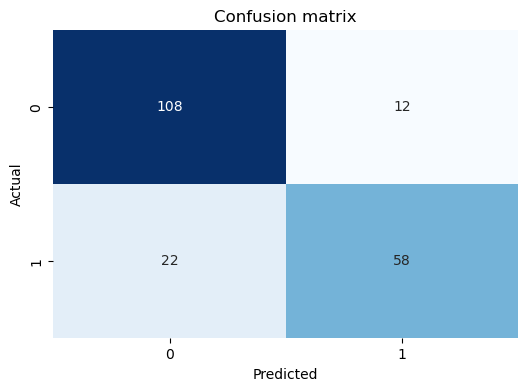

In [216]:
cm=confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title("Confusion matrix")
plt.show()

In [217]:
y_pred_proba_train=logreg.predict_proba(X_train)
loss=log_loss(y_train, y_pred_proba_train)
print("The train loss of Logistric regression is",loss)
# 가중치를 부여한 경우 0.480334449434861인 반면 부여하지 않은 경우 0.46167789608418497로 더 낮음

The train loss of Logistric regression is 0.45486688177812806


In [218]:
X_tr = tr_2[cat_cols + con_cols]
y_tr = tr_2[target_col]
X_te = te_2[cat_cols + con_cols]
y_te = te_2[target_col]
preprocessor=ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), con_cols), ("cat", OneHotEncoder(drop="first"), cat_cols)
    ]
)
# 위에서 찾은 c와 max_iter 적용
clf = Pipeline(steps=[
    ("preprocessor", preprocessor), 
    ("classifier", LogisticRegression(solver='liblinear', C=0.8, max_iter=300, class_weight='balanced'))
])
# clf = Pipeline(steps=[
#     ("preprocessor", preprocessor), 
#     ("classifier", LogisticRegression(solver='liblinear', C=0.8, max_iter=200))
# ])
clf.fit(X_tr, y_tr.values.ravel())
y_pred=clf.predict(X_te)
y_proba=clf.predict_proba(X_te)[:, 1]
print("Classification Report:\n", classification_report(y_te, y_pred))

# 가중치를 할 경우 정확도 81, 아닐 때는 83 

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.82      0.83       120
           1       0.74      0.79      0.76        80

    accuracy                           0.81       200
   macro avg       0.80      0.80      0.80       200
weighted avg       0.81      0.81      0.81       200



In [219]:
# 첫번째와 두번째를 실시해본 결과 첫번째 것이 더욱 성능 높음 -> 이외 다른 요소 건드려보기

In [220]:
# fare 값을 보면 전부 왼쪽으로 쏠려 있으나 이상치 존재 -> 로그변환 해서 사용해보기
tr_3 = tr.drop(columns=["Name","Cabin","Ticket","Embarked","PassengerId"])
te_3 = te.drop(columns=["Name","Cabin","Ticket","Embarked","PassengerId"])
tr_3["Fare"] = np.log1p(tr_3["Fare"])
te_3["Fare"] = np.log1p(te_3["Fare"])
cat_cols=["Sex", "Pclass","SibSp", "Parch"]
con_cols=["Age","Fare"]
target_col=["Survived"]

In [221]:
combined = pd.concat([tr_3, te_3], axis=0)
combined_dummies = pd.get_dummies(combined, columns=cat_cols, drop_first=True)
tr3 = combined_dummies.iloc[:len(tr_3), :].copy()
te3 = combined_dummies.iloc[len(tr_3):, :].copy()
X_train=tr3.drop(['Survived'], axis=1)
y_train=tr3[['Survived']]
X_test=te3.drop(['Survived'], axis=1)
y_test=te3[['Survived']]

In [222]:
for c in [0.2, 0.4, 0.6, 0.8, 1.0]:
    logreg= LogisticRegression(penalty='l2', C=c, max_iter=1000)
    logreg.fit(X_train, y_train.values.ravel())
    y_pred_proba=logreg.predict_proba(X_test)
    y_pred = np.argmax(y_pred_proba, axis=1)
    print("c의 값은 : ",c)
    print("The train accuracy score of Logistric regression is ", accuracy_score(y_train, logreg.predict(X_train)))
    print("The test accuracy score of Logistric Regression is ", accuracy_score(y_test, y_pred))
# 결과 0.8이 적합하다 판단(가중치 있어도 동일)

c의 값은 :  0.2
The train accuracy score of Logistric regression is  0.7762938230383973
The test accuracy score of Logistric Regression is  0.79
c의 값은 :  0.4
The train accuracy score of Logistric regression is  0.7913188647746243
The test accuracy score of Logistric Regression is  0.82
c의 값은 :  0.6
The train accuracy score of Logistric regression is  0.8046744574290484
The test accuracy score of Logistric Regression is  0.815
c의 값은 :  0.8
The train accuracy score of Logistric regression is  0.8080133555926544
The test accuracy score of Logistric Regression is  0.825
c의 값은 :  1.0
The train accuracy score of Logistric regression is  0.8096828046744574
The test accuracy score of Logistric Regression is  0.825


In [223]:
for max in [200, 400, 600, 800, 1000]:
    logreg = LogisticRegression(penalty='l2', C=0.8, max_iter=max)   
    logreg.fit(X_train, y_train.values.ravel())
    y_pred_proba=logreg.predict_proba(X_test)
    y_pred = np.argmax(y_pred_proba, axis=1)
    print("max_iter의 값은 : ",max)
    print("The train accuracy score of Logistric regression is ", accuracy_score(y_train, logreg.predict(X_train)))
    print("The test accuracy score of Logistric Regression is ", accuracy_score(y_test, y_pred))
# 200보다 크더라도 결과 변화 없음 -> 200으로 선정(가중치 있어도 동일일)

max_iter의 값은 :  200
The train accuracy score of Logistric regression is  0.8080133555926544
The test accuracy score of Logistric Regression is  0.825
max_iter의 값은 :  400
The train accuracy score of Logistric regression is  0.8080133555926544
The test accuracy score of Logistric Regression is  0.825
max_iter의 값은 :  600
The train accuracy score of Logistric regression is  0.8080133555926544
The test accuracy score of Logistric Regression is  0.825
max_iter의 값은 :  800
The train accuracy score of Logistric regression is  0.8080133555926544
The test accuracy score of Logistric Regression is  0.825
max_iter의 값은 :  1000
The train accuracy score of Logistric regression is  0.8080133555926544
The test accuracy score of Logistric Regression is  0.825


In [224]:
logreg = LogisticRegression(penalty='l2', C=0.8, max_iter=200)   
logreg.fit(X_train, y_train.values.ravel())
y_pred_proba=logreg.predict_proba(X_test)
y_pred = np.argmax(y_pred_proba, axis=1)
print("The train accuracy score of Logistric regression is ", accuracy_score(y_train, logreg.predict(X_train)))
print("The test accuracy score of Logistric Regression is ", accuracy_score(y_test, y_pred))

The train accuracy score of Logistric regression is  0.8080133555926544
The test accuracy score of Logistric Regression is  0.825


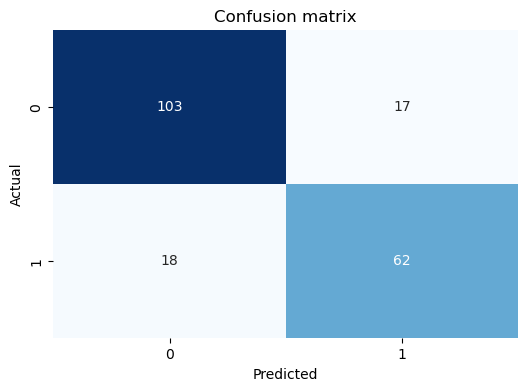

In [225]:
cm=confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title("Confusion matrix")
plt.show()

In [226]:
y_pred_proba_train=logreg.predict_proba(X_train)
loss=log_loss(y_train, y_pred_proba_train)
print("The train loss of Logistric regression is",loss)

The train loss of Logistric regression is 0.45700521263093363


In [227]:
X_train = tr_3[cat_cols + con_cols]
y_train = tr_3[target_col]
X_test = te_3[cat_cols + con_cols]
y_test = te_3[target_col]
preprocessor=ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), con_cols), ("cat", OneHotEncoder(drop="first"), cat_cols)
    ]
)
clf = Pipeline(steps=[
    ("preprocessor", preprocessor), 
    ("classifier", LogisticRegression(solver='liblinear', C=0.8, max_iter=200, class_weight='balanced'))
])
# clf = Pipeline(steps=[
#     ("preprocessor", preprocessor), 
#     ("classifier", LogisticRegression(solver='liblinear', C=0.8, max_iter=200))
# ])
clf.fit(X_train, y_train.values.ravel())
y_pred=clf.predict(X_test)
y_proba=clf.predict_proba(X_test)[:, 1]
print("Classification Report:\n", classification_report(y_test, y_pred))

Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.81      0.84       120
           1       0.74      0.84      0.79        80

    accuracy                           0.82       200
   macro avg       0.81      0.82      0.82       200
weighted avg       0.83      0.82      0.82       200



In [228]:
# 지금까지 실시한 3가지 모델을 분석한 결과 첫번째가 가장 좋음...
# 합치면 다른 결과일까?

In [229]:
tr_4 = tr.drop(columns=["Name","Cabin","Ticket","PassengerId"])
te_4 = te.drop(columns=["Name","Cabin","Ticket","PassengerId"])
tr_4["Fare"] = np.log1p(tr_4["Fare"])
te_4["Fare"] = np.log1p(te_4["Fare"])
cat_cols=["Sex", "Pclass","SibSp", "Parch","Embarked"]
con_cols=["Age","Fare"]
target_col=["Survived"]

In [230]:
combined = pd.concat([tr_4, te_4], axis=0)
combined_dummies = pd.get_dummies(combined, columns=cat_cols, drop_first=True)
tr4 = combined_dummies.iloc[:len(tr_4), :].copy()
te4 = combined_dummies.iloc[len(tr_4):, :].copy()
X_train=tr4.drop(['Survived'], axis=1)
y_train=tr4[['Survived']]
X_test=te4.drop(['Survived'], axis=1)
y_test=te4[['Survived']]

In [231]:
for c in [1.0,1.2, 1.4, 1.6, 1.8, 2.0]:
    logreg= LogisticRegression(penalty='l2', C=c, max_iter=1000)
    logreg.fit(X_train, y_train.values.ravel())
    y_pred_proba=logreg.predict_proba(X_test)
    y_pred = np.argmax(y_pred_proba, axis=1)
    print("c의 값은 : ",c)
    print("The train accuracy score of Logistric regression is ", accuracy_score(y_train, logreg.predict(X_train)))
    print("The test accuracy score of Logistric Regression is ", accuracy_score(y_test, y_pred))
# c를 비교해본 결과 1.6까지는 계속 test accuracy가 증가하지만 train accuracy는 증가하지 않는 것으로 보아 과적합은 아니라 판단 -> 1.6으로 선정정

c의 값은 :  1.0
The train accuracy score of Logistric regression is  0.8096828046744574
The test accuracy score of Logistric Regression is  0.83
c의 값은 :  1.2
The train accuracy score of Logistric regression is  0.8096828046744574
The test accuracy score of Logistric Regression is  0.835
c의 값은 :  1.4
The train accuracy score of Logistric regression is  0.8080133555926544
The test accuracy score of Logistric Regression is  0.835
c의 값은 :  1.6
The train accuracy score of Logistric regression is  0.8096828046744574
The test accuracy score of Logistric Regression is  0.845
c의 값은 :  1.8
The train accuracy score of Logistric regression is  0.8113522537562604
The test accuracy score of Logistric Regression is  0.845
c의 값은 :  2.0
The train accuracy score of Logistric regression is  0.8096828046744574
The test accuracy score of Logistric Regression is  0.845


In [232]:
for max in [200, 400, 600, 800, 1000]:
    logreg = LogisticRegression(penalty='l2', C=1.6, max_iter=max)   
    logreg.fit(X_train, y_train.values.ravel())
    y_pred_proba=logreg.predict_proba(X_test)
    y_pred = np.argmax(y_pred_proba, axis=1)
    print("max_iter의 값은 : ",max)
    print("The train accuracy score of Logistric regression is ", accuracy_score(y_train, logreg.predict(X_train)))
    print("The test accuracy score of Logistric Regression is ", accuracy_score(y_test, y_pred))
# 200일때 이미 수렴을 하였기 때문에 200으로 선정

max_iter의 값은 :  200
The train accuracy score of Logistric regression is  0.8096828046744574
The test accuracy score of Logistric Regression is  0.845
max_iter의 값은 :  400
The train accuracy score of Logistric regression is  0.8096828046744574
The test accuracy score of Logistric Regression is  0.845
max_iter의 값은 :  600
The train accuracy score of Logistric regression is  0.8096828046744574
The test accuracy score of Logistric Regression is  0.845
max_iter의 값은 :  800
The train accuracy score of Logistric regression is  0.8096828046744574
The test accuracy score of Logistric Regression is  0.845
max_iter의 값은 :  1000
The train accuracy score of Logistric regression is  0.8096828046744574
The test accuracy score of Logistric Regression is  0.845


In [233]:
logreg = LogisticRegression(penalty='l2', C=1.6, max_iter=200)   
logreg.fit(X_train, y_train.values.ravel())
y_pred_proba=logreg.predict_proba(X_test)
y_pred = np.argmax(y_pred_proba, axis=1)
print("The train accuracy score of Logistric regression is ", accuracy_score(y_train, logreg.predict(X_train)))
print("The test accuracy score of Logistric Regression is ", accuracy_score(y_test, y_pred))

The train accuracy score of Logistric regression is  0.8096828046744574
The test accuracy score of Logistric Regression is  0.845


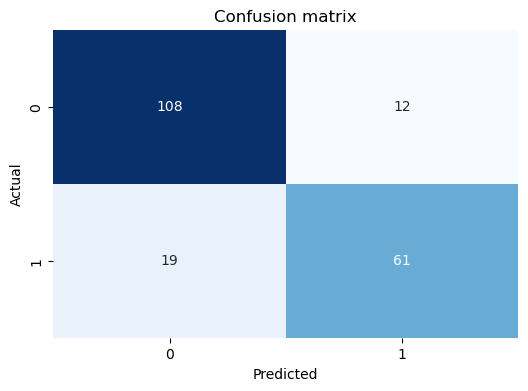

In [234]:
cm=confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title("Confusion matrix")
plt.show()

In [235]:
y_pred_proba_train=logreg.predict_proba(X_train)
loss=log_loss(y_train, y_pred_proba_train)
print("The train loss of Logistric regression is",loss)

The train loss of Logistric regression is 0.4513958829927849


In [236]:
X_train = tr_4[cat_cols + con_cols]
y_train = tr_4[target_col]
X_test = te_4[cat_cols + con_cols]
y_test = te_4[target_col]
preprocessor=ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), con_cols), ("cat", OneHotEncoder(drop="first"), cat_cols)
    ]
)
# clf = Pipeline(steps=[
#     ("preprocessor", preprocessor), 
#     ("classifier", LogisticRegression(solver='liblinear', C=1.6, max_iter=200, class_weight='balanced'))
# ])
clf = Pipeline(steps=[
    ("preprocessor", preprocessor), 
    ("classifier", LogisticRegression(solver='liblinear', C=1.6, max_iter=200))
])
clf.fit(X_train, y_train.values.ravel())
y_pred=clf.predict(X_test)
y_proba=clf.predict_proba(X_test)[:, 1]
print("Classification Report:\n", classification_report(y_test, y_pred))

Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.89      0.86       120
           1       0.82      0.74      0.78        80

    accuracy                           0.83       200
   macro avg       0.83      0.81      0.82       200
weighted avg       0.83      0.83      0.83       200



In [237]:
# 4번째의 경우 83% 기록.. -> 이름에서 중간에 mr 같은 경우 성별, 지위 등을 나타내므로 생존률과 관계 있을수도 있음 

In [238]:
# 이름에서 .으로 끝나는 것의 앞부분 (mr, ms 같은 것)들을 추출
# 별로 사용되지 않은 칭호는 Rare로 바꾸고, 의미가 같은 것들을 같은 용어로 변경
tr_5 = tr.drop(columns=["Cabin","Ticket","PassengerId"])
te_5 = te.drop(columns=["Cabin","Ticket","PassengerId"])
tr_5["Fare"] = np.log1p(tr_5["Fare"])
te_5["Fare"] = np.log1p(te_5["Fare"])
cat_cols=["Sex", "Pclass","SibSp", "Parch","Embarked","Name"]
con_cols=["Age","Fare"]
target_col=["Survived"]

In [239]:
combined = pd.concat([tr_5, te_5], axis=0)
combined_dummies = pd.get_dummies(combined, columns=cat_cols, drop_first=True)
tr5 = combined_dummies.iloc[:len(tr_1), :].copy()
te5 = combined_dummies.iloc[len(tr_1):, :].copy()
X_train=tr5.drop(['Survived'], axis=1)
y_train=tr5[['Survived']]
X_test=te5.drop(['Survived'], axis=1)
y_test=te5[['Survived']]

In [240]:
for c in [0.2, 0.4, 0.6, 0.8, 1.0]:
    logreg= LogisticRegression(penalty='l2', C=c, max_iter=1000)
    logreg.fit(X_train, y_train.values.ravel())
    y_pred_proba=logreg.predict_proba(X_test)
    y_pred = np.argmax(y_pred_proba, axis=1)
    print("c의 값은 : ",c)
    print("The train accuracy score of Logistric regression is ", accuracy_score(y_train, logreg.predict(X_train)))
    print("The test accuracy score of Logistric Regression is ", accuracy_score(y_test, y_pred))
# 결과 0.6일때 과적합 없이 가장 적절하다 판단

c의 값은 :  0.2
The train accuracy score of Logistric regression is  0.7996661101836394
The test accuracy score of Logistric Regression is  0.835
c의 값은 :  0.4
The train accuracy score of Logistric regression is  0.8113522537562604
The test accuracy score of Logistric Regression is  0.85
c의 값은 :  0.6
The train accuracy score of Logistric regression is  0.8180300500834724
The test accuracy score of Logistric Regression is  0.855
c의 값은 :  0.8
The train accuracy score of Logistric regression is  0.8196994991652755
The test accuracy score of Logistric Regression is  0.855
c의 값은 :  1.0
The train accuracy score of Logistric regression is  0.8213689482470785
The test accuracy score of Logistric Regression is  0.855


In [241]:
for max in [200, 400, 600, 800, 1000]:
    logreg = LogisticRegression(penalty='l2', C=0.6, max_iter=max)   
    logreg.fit(X_train, y_train.values.ravel())
    y_pred_proba=logreg.predict_proba(X_test)
    y_pred = np.argmax(y_pred_proba, axis=1)
    print("max_iter의 값은 : ",max)
    print("The train accuracy score of Logistric regression is ", accuracy_score(y_train, logreg.predict(X_train)))
    print("The test accuracy score of Logistric Regression is ", accuracy_score(y_test, y_pred))
# 이전과 마찬가지로 200일때 이미 수렴하기 때문에 200으로 선정정

max_iter의 값은 :  200
The train accuracy score of Logistric regression is  0.8180300500834724
The test accuracy score of Logistric Regression is  0.855
max_iter의 값은 :  400
The train accuracy score of Logistric regression is  0.8180300500834724
The test accuracy score of Logistric Regression is  0.855
max_iter의 값은 :  600
The train accuracy score of Logistric regression is  0.8180300500834724
The test accuracy score of Logistric Regression is  0.855
max_iter의 값은 :  800
The train accuracy score of Logistric regression is  0.8180300500834724
The test accuracy score of Logistric Regression is  0.855
max_iter의 값은 :  1000
The train accuracy score of Logistric regression is  0.8180300500834724
The test accuracy score of Logistric Regression is  0.855


In [242]:
logreg = LogisticRegression(penalty='l2', C=0.6, max_iter=200)   
logreg.fit(X_train, y_train.values.ravel())
y_pred_proba=logreg.predict_proba(X_test)
y_pred = np.argmax(y_pred_proba, axis=1)
print("The train accuracy score of Logistric regression is ", accuracy_score(y_train, logreg.predict(X_train)))
print("The test accuracy score of Logistric Regression is ", accuracy_score(y_test, y_pred))

The train accuracy score of Logistric regression is  0.8180300500834724
The test accuracy score of Logistric Regression is  0.855


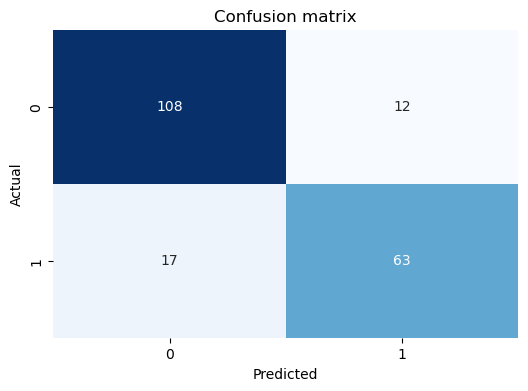

In [243]:
cm=confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title("Confusion matrix")
plt.show()

In [244]:
y_pred_proba_train=logreg.predict_proba(X_train)
loss=log_loss(y_train, y_pred_proba_train)
print("The train loss of Logistric regression is",loss)

The train loss of Logistric regression is 0.43994052380948445


In [245]:
X_train = tr_5[cat_cols + con_cols]
y_train = tr_5[target_col]
X_test = te_5[cat_cols + con_cols]
y_test = te_5[target_col]
preprocessor=ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), con_cols), ("cat", OneHotEncoder(drop="first"), cat_cols)
    ]
)
# clf = Pipeline(steps=[
#     ("preprocessor", preprocessor), 
#     ("classifier", LogisticRegression(solver='liblinear', C=0.6, max_iter=200, class_weight='balanced'))
# ])
clf = Pipeline(steps=[
    ("preprocessor", preprocessor), 
    ("classifier", LogisticRegression(solver='liblinear', C=0.6, max_iter=200))
])
clf.fit(X_train, y_train.values.ravel())
y_pred=clf.predict(X_test)
y_proba=clf.predict_proba(X_test)[:, 1]
print("Classification Report:\n", classification_report(y_test, y_pred))
# 전체 정확도 85% (가중치 적용시 81)

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.91      0.88       120
           1       0.85      0.76      0.80        80

    accuracy                           0.85       200
   macro avg       0.85      0.84      0.84       200
weighted avg       0.85      0.85      0.85       200



In [246]:
# 5번째 모델의 경우 pipeline을 통한 정확도는 0.85
# -> 5번째 모델이 가장 적합
# 이후 코드는 확인을 위해 실행되지 않도록 주석처리리

In [247]:
# tr_5 = tr.drop(columns=["Cabin","Ticket","PassengerId"])
# te_5 = te.drop(columns=["Cabin","Ticket","PassengerId"])
# tr_5["Fare"] = np.log1p(tr_5["Fare"])
# te_5["Fare"] = np.log1p(te_5["Fare"])
# cat_cols=["Sex", "Pclass","SibSp", "Parch","Embarked","Name"]
# con_cols=["Age","Fare"]
# target_col=["Survived"]
# combined = pd.concat([tr_5, te_5], axis=0)
# combined_dummies = pd.get_dummies(combined, columns=cat_cols, drop_first=True)
# tr5 = combined_dummies.iloc[:len(tr_1), :].copy()
# te5 = combined_dummies.iloc[len(tr_1):, :].copy()
# X_train=tr5.drop(['Survived'], axis=1)
# y_train=tr5[['Survived']]
# X_test=te5.drop(['Survived'], axis=1)
# y_test=te5[['Survived']]

In [ ]:
# test=pd.read_csv("test.csv")
# test.isnull().sum()
# test["Age"] = test["Age"].fillna(a)
# test["Age"] = test["Age"].round()

In [ ]:
# test = test.drop(columns=["Cabin","Ticket","PassengerId"])
# test["Embarked"] = test["Embarked"].fillna(b)
# test["Fare"] = np.log1p(test["Fare"])
# test['Name'] = test['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)
# test['Name'] = test['Name'].replace(['Lady', 'Countess', 'Capt', 'Col','Don', 'Dr', 'Major', 'Rev', 'Sir','Jonkheer', 'Dona'], 'Rare')
# test['Name'] = test['Name'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
# cat_cols=["Sex", "Pclass","SibSp", "Parch","Embarked","Name"]
# con_cols=["Age","Fare"]

In [ ]:
# test1=test.copy()
# test1 = pd.get_dummies(test1, columns=cat_cols, drop_first=True)
# missing_cols = set(X_train.columns) - set(test1.columns)
# for col in missing_cols:
#     test1[col] = 0
# test1 = test1[X_train.columns]

In [ ]:
# y_pred_test=logreg.predict(test1)

In [ ]:
# test_raw = pd.read_csv("test.csv")
# submission = pd.DataFrame({
#     "PassengerId": test_raw["PassengerId"],
#     "Survived": y_pred_test
# })
# submission.to_csv("HW1_test.csv", index=False)